# The symbolic system

Notebook `python/Notebooks/tutorialSymbolicSystem.ipynb`.

Two mass points hang on spring-dampers under gravity. The system is built with the user items of
`exudyn.symbolics.userItems` - the same Create functions as with `mbs` -, recorded, and `SymbolicSystem` gives its
equations of motion as expressions, evaluates them and integrates them with the solvers of `exudyn.symbolics.solvers`.
The symbolic system is a replicate of `mbs`: its solution is written into `mbs`, so the sensors, the solution file and
the solution viewer show it as after `mbs.SolveDynamic`.

In [1]:
import exudyn as exu
from exudyn.utilities import *  #includes itemInterface and rigidBodyUtilities
from exudyn.symbolics.userItems import UserItemCreator
from exudyn.symbolics.systemModel import SymbolicSystem
from exudyn.symbolics.solvers import SolveGeneralizedAlpha
import numpy as np

SC = exu.SystemContainer()
mbs = SC.AddSystem()
creator = UserItemCreator(mbs)  #creator = mbs builds the same system of built-in items

The items, created as with `mbs`; `Record` replaces the Python user functions of the user items by symbolic ones, one
recording per kind of item:

In [2]:
ground = creator.CreateGround()
m0 = creator.CreateMassPoint(referencePosition=[0.5, 0, 0], mass=1., gravity=[0, -9.81, 0], drawSize=0.1)
m1 = creator.CreateMassPoint(referencePosition=[1.0, 0, 0], mass=0.5, gravity=[0, -9.81, 0], drawSize=0.1)
creator.CreateSpringDamper(itemNumbers=[ground, m0], stiffness=200., damping=1.)
creator.CreateSpringDamper(itemNumbers=[m0, m1], stiffness=100., damping=0.5)
sensor = mbs.AddSensor(SensorBody(bodyNumber=m1, storeInternal=True, outputVariableType=exu.OutputVariableType.Position))
creator.Record()
mbs.Assemble()

`SymbolicSystem(mbs)` collects the equations $\Mm(\qv, t)\,\ddot\qv = \fv(\qv, \dot\qv, t)$ of the recorded items.
`Equations()` gives them as `exudyn.symbolic` expressions, or as sympy expressions if sympy is installed:

In [3]:
system = SymbolicSystem(mbs)
print('ODE2 coordinates:', system.nODE2)
try:
    import sympy
    equations = system.Equations(format='sympy')
    print('mass matrix:', equations['massMatrix'])
    print('force on coordinate 4:', sympy.simplify(equations['ODE2RHS'][4]))
except ImportError:
    equations = system.Equations()
    print('force on coordinate 4:', equations['ODE2RHS'][4])

ODE2 coordinates: 6
mass matrix: Matrix([[1.00000000000000, 0, 0, 0, 0, 0], [0, 1.00000000000000, 0, 0, 0, 0], [0, 0, 1.00000000000000, 0, 0, 0], [0, 0, 0, 0.500000000000000, 0, 0], [0, 0, 0, 0, 0.500000000000000, 0], [0, 0, 0, 0, 0, 0.500000000000000]])
force on coordinate 4: (-4.905*(q1 - q4)**2 + 1.0*(q1 - q4)*(0.5*(q1 - q4)*(q_t1 - q_t4) + 0.5*(q2 - q5)*(q_t2 - q_t5) - 0.5*(q_t0 - q_t3)*(-q0 + q3 + 0.5) + (100.0*sqrt((q1 - q4)**2 + (q2 - q5)**2 + (-q0 + q3 + 0.5)**2) - 50.0)*sqrt((q1 - q4)**2 + (q2 - q5)**2 + (-q0 + q3 + 0.5)**2)) - 4.905*(q2 - q5)**2 - 4.905*(-q0 + q3 + 0.5)**2)/((q1 - q4)**2 + (q2 - q5)**2 + (-q0 + q3 + 0.5)**2)


The system evaluates its equations at any state, e.g. the forces at the initial state - gravity only, as the springs
are at their reference lengths:

In [4]:
(q, q_t) = system.InitialState()
print('forces at the initial state:', system.ODE2RHS(q, q_t, 0.))

forces at the initial state: [ 0.    -9.81   0.     0.    -4.905  0.   ]


`SolveGeneralizedAlpha` integrates the system as Exudyn's implicit solver does, with the same `SimulationSettings`. It
writes each step into `mbs`, so the sensor has the solution and the solution file is written:

In [5]:
simulationSettings = exu.SimulationSettings()
simulationSettings.timeIntegration.numberOfSteps = 1000
simulationSettings.timeIntegration.endTime = 2
simulationSettings.solution.file.writePeriod = 0.01
simulationSettings.timeIntegration.verboseMode = 0
result = SolveGeneralizedAlpha(system, simulationSettings)
print('steps:', result['steps'], ', Newton iterations:', result['newtonIterations'])
positionSymbolic = mbs.GetSensorValues(sensor)
print('position of mass 1 at t=2:', positionSymbolic)

steps: 1000 , Newton iterations: 1898
position of mass 1 at t=2: [ 0.76372249 -0.99500689  0.        ]


The solution file of the symbolic solver is shown by the solution viewer as any other (no window opens when the
notebook is run for the documentation), and the sensor as after `mbs.SolveDynamic`:

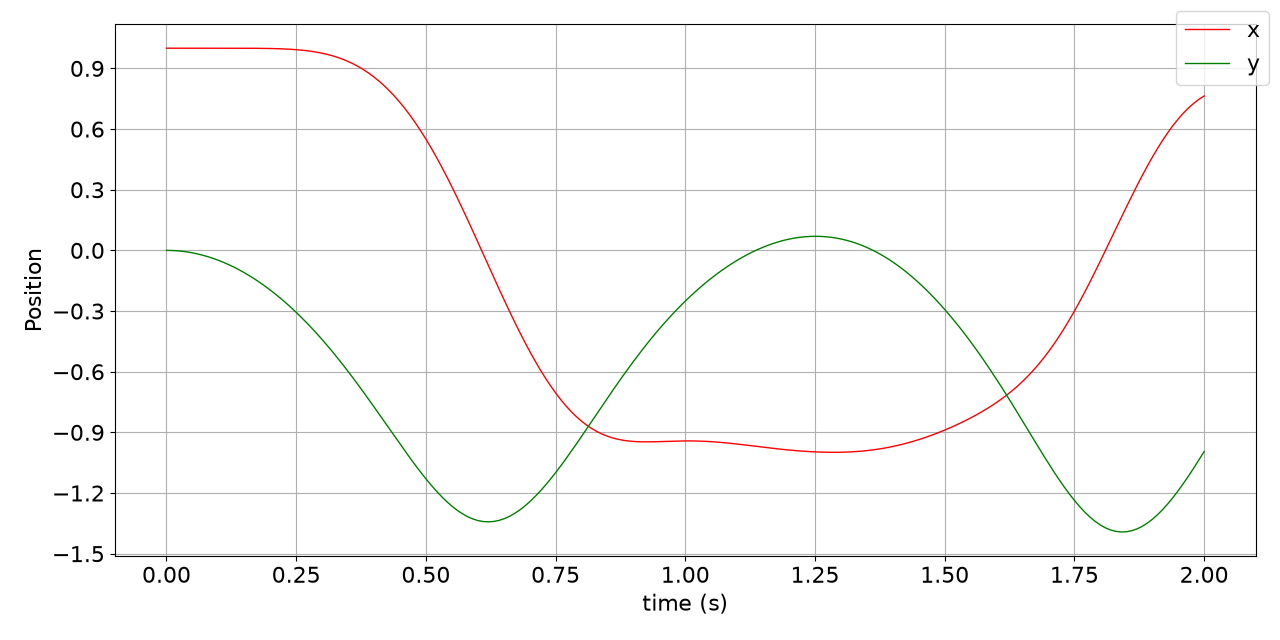

In [6]:
mbs.SolutionViewer()
mbs.PlotSensor(sensor, components=[0, 1], labels=['x', 'y'])

The same system integrated by Exudyn's solver gives the same solution, within the Newton tolerance:

In [7]:
mbs.SolveDynamic(simulationSettings)
print('difference to SolveDynamic:', np.max(np.abs(mbs.GetSensorValues(sensor) - positionSymbolic)))

difference to SolveDynamic: 6.579874423096044e-10


`GetFlatProgram` exports the equations as a program of scalar and vector operations - here the first lines of the
Python version -, the start of an evaluation outside Exudyn:

In [8]:
code = system.GetFlatProgram(format='Python')
print('\n'.join(code.split('\n')[:8]))

t5 = (0.5 + q[0])
t10 = [t5, q[1], q[2]]
t12 = (t10 - [0,0,0])
t13 = (t12 @ t12)
t14 = sqrt(t13)
t15 = (t14 - 0.5)
t16 = (200 * t15)
t17 = (1 / t14)
